# Datasets and the Lin-KK Test

D1, D2 and D3 are public datasets of impedance spectra of lithium-ion cells at several states of
charge. A workbook in `datasets/` holds one spectrum per state $v$. A spectrum is the complex
function $Z(\omega) = \mathrm{Re}\,Z + j\,\mathrm{Im}\,Z$ of the angular frequency
$\omega = 2\pi f$. The workbook gives its values at the measured frequencies $f$. Running all cells
takes less than 1 min. With `DOWNLOAD_RAW = True` the raw data (366 MB) are downloaded first and
the workbooks are built again from them.

In [1]:
%matplotlib inline
import contextlib
import io
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import cm
from matplotlib.colors import Normalize

from eis import data, datasets, env, linkk, rawdata
from eis.plotting import COL, apply_style

RECOMPUTE = False      # True computes every output file again
DOWNLOAD_RAW = False   # True downloads the raw data (366 MB) into datasets/raw/
RAW = os.path.join(env.DIR_DATASETS, "raw")
REBUILT = os.path.join(env.DIR_DATASETS, "rebuilt")
# folder of the output files (experiments/ in the repository root)
OUT = os.path.join(env.DIR_BASE, "experiments")
os.makedirs(OUT, exist_ok=True)

apply_style()

## Raw Data and Workbooks

Each workbook averages the public raw spectra of its dataset over a group of cells. The sources
and the processing are in `datasets/README.md`. The build reads 513 raw files. When the folder
`datasets/raw/` exists, `eis.rawdata.check_files` checks the MD5 checksum of each of them. Then
`eis.rawdata.build_workbooks` builds the three workbooks into `datasets/rebuilt/`, and
`compare_workbooks` compares each of them with the workbook in `datasets/`. With
`DOWNLOAD_RAW = True`, `eis.rawdata.fetch` first downloads the raw archives into `datasets/raw/`.

In [2]:
if DOWNLOAD_RAW:
    for name in rawdata.SOURCES:
        rawdata.fetch(name, RAW)
if os.path.isdir(RAW):
    rawdata.check_files(RAW, list(rawdata.SOURCES))
    rows = []
    for path in rawdata.build_workbooks(RAW, REBUILT):
        name = os.path.basename(path)
        same, diff = rawdata.compare_workbooks(path, os.path.join(env.DIR_DATASETS, name))
        rows.append({"workbook": name, "sheets": diff["sheet"].nunique(),
                     "numeric columns": int((diff["note"] == "").sum()),
                     "largest difference": diff["max_abs_diff"].max(),
                     "same values": same})
    print(pd.DataFrame(rows).to_string(index=False))
else:
    print("The folder datasets/raw/ does not exist. DOWNLOAD_RAW = True downloads the raw data.")

513 raw files checked: all MD5 values equal raw_files.md5


               workbook  sheets  numeric columns  largest difference  same values
  D1_zhang_dataset.xlsx       7               47                 0.0         True
 D2_rashid_dataset.xlsx       6               42                 0.0         True
D3_mustafa_dataset.xlsx      21              147                 0.0         True


## Summary of the Datasets

Each workbook is read with `eis.data.load_dataset` into a table with one row per point. The
columns `f` (Hz) and `omega` (rad/s) hold $f$ and $\omega$. The values of $\mathrm{Re}\,Z$ and
$\mathrm{Im}\,Z$ (ohm) are in `zr` and `zj`. The state label $v$ is in the column `v` (column
`v_actual` of the sheet `meta`). The column `v_nom` holds the name of the sheet of the state.

The summary table has one row per dataset. It lists the chemistry, the number of states $n_v$
and the frequency range. It also gives the number of frequencies $n_\omega$ per state and the
mean of $\lvert Z\rvert$ over all points.

In [3]:
CHEMISTRY = {"D1_zhang": "LCO/graphite", "D2_rashid": "NMC", "D3_mustafa": "LFP"}

rows = []
for name, chemistry in CHEMISTRY.items():
    df = data.load_dataset(name)
    per_state = df.groupby("v_nom").size()
    rows.append({
        "dataset": name.split("_")[0],
        "chemistry": chemistry,
        "n_v": df["v_nom"].nunique(),
        "frequency range": f"{df['f'].min():.2g} Hz to {df['f'].max() / 1e3:.2g} kHz",
        "n_omega": ", ".join(str(n) for n in sorted(per_state.unique())),
        "mean |Z| (ohm)": f"{np.hypot(df['zr'], df['zj']).mean():.3g}",
    })
pd.DataFrame(rows).set_index("dataset")

,chemistry,n_v,frequency range,n_omega,mean |Z| (ohm)
dataset,,,,,
D1,LCO/graphite,6,0.02 Hz to 20 kHz,60,1.03
D2,NMC,5,0.01 Hz to 10 kHz,61,0.0314
D3,LFP,20,0.01 Hz to 1 kHz,28,0.0806


## Measured Spectra

The figures show every spectrum in the Nyquist view ($-\mathrm{Im}\,Z$ against
$\mathrm{Re}\,Z$). Each dataset has its own figure, and each curve is one state colored by its
label $v$. The axis limits leave out a state whose largest value exceeds 1.8 times that of the
next state. The upper-boundary state of D3 is such a state and runs past the frame of the D3
figure.

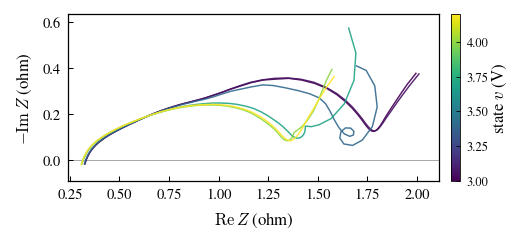

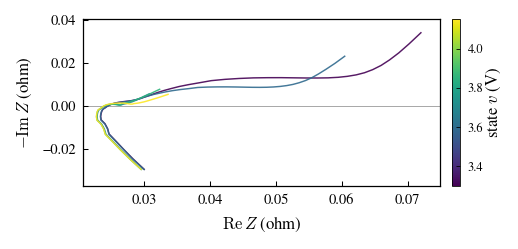

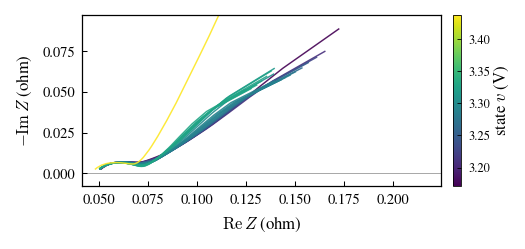

In [4]:
CMAP = "viridis"
OUTLIER_RATIO = 1.8   # a state above 1.8 times the next state is left out of the view


def view_cap(per_state_max):
    """Return the upper limit of the view without a single state far above the others."""
    vs = sorted(per_state_max)
    if len(vs) >= 2 and vs[-1] > OUTLIER_RATIO * vs[-2]:
        return vs[-2]
    return vs[-1]


def make_panel(key):
    df = data.load_dataset(key)
    states = sorted(float(s) for s in df.v_nom.unique())
    norm = Normalize(vmin=min(states), vmax=max(states))
    sm = cm.ScalarMappable(norm=norm, cmap=CMAP)
    sm.set_array([])

    fig, ax = plt.subplots(figsize=(COL, 1.7))
    re_max, im_max, im_min = [], [], []
    for s in states:
        d = df[np.isclose(df.v_nom, s)].sort_values("f", ascending=False)
        x, y = d.zr.to_numpy(), -d.zj.to_numpy()
        ax.plot(x, y, "-", color=sm.to_rgba(s), lw=0.7, alpha=0.9)
        re_max.append(x.max())
        im_max.append(y.max())
        im_min.append(y.min())

    xhi, yhi, ylo = view_cap(re_max), view_cap(im_max), min(im_min)
    xr, yr = xhi - df.zr.min(), yhi - ylo
    ax.set_xlim(df.zr.min() - 0.04 * xr, xhi + 0.06 * xr)
    ax.set_ylim(ylo - 0.12 * yr, yhi + 0.10 * yr)
    ax.axhline(0.0, color="0.6", lw=0.4, zorder=0)

    ax.set_xlabel(r"$\mathrm{Re}\,Z$ (ohm)")
    ax.set_ylabel(r"$-\mathrm{Im}\,Z$ (ohm)")
    cb = fig.colorbar(sm, ax=ax, fraction=0.046, pad=0.03)
    cb.set_label(r"state $v$ (V)", labelpad=1)
    cb.ax.tick_params(labelsize=6, width=0.4, length=2)
    cb.outline.set_linewidth(0.4)
    fig.tight_layout()
    return fig


for key in datasets.DATASETS:
    make_panel(key)

## Lin-KK Test

The Kramers-Kronig (K-K) relation links $\mathrm{Re}\,Z$ and $\mathrm{Im}\,Z$ of every causal,
stable and linear system. The linear K-K test (Lin-KK) fits each measured spectrum with a model
whose every term satisfies this relation:

$$Z_\mathrm{fit}(\omega) = R_0 + \sum_{k=1}^{M} \frac{R_k}{1 + j\omega\tau_k} + j\omega L
+ \frac{1}{j\omega C}.$$

The time constants $\tau_k$ are fixed and log-spaced from $1/(2\pi f_\mathrm{max})$ to
$1/(2\pi f_\mathrm{min})$. The parameters $R_0$, $R_k$, $L$ and $1/C$ solve a linear
least-squares problem in the residuals divided by $\lvert Z\rvert$. The relative residual
$\lvert\Delta\rvert = \lvert Z - Z_\mathrm{fit}\rvert / \lvert Z\rvert$ measures the part of the
spectrum that the K-K model cannot fit.

Two fits are made per spectrum (`eis.linkk.run_dataset`). The automatic fit increases $M$ until
$\mu = 1 - \sum_{R_k<0}\lvert R_k\rvert / \sum_{R_k\ge 0}\lvert R_k\rvert$ is at most the cutoff
$c = 0.85$, or until $M = \max(5, n_\omega - 1)$. The matched fit uses $M = 20$ at every state.
Both fit the real and the imaginary parts together (`fit_type="complex"`) and include the term
$1/(j\omega C)$ (`add_cap=True`).

In [5]:
LINKK_FILES = [os.path.join(OUT, name) for name in
               ("01_linkk_perstate.csv", "01_linkk_residuals.csv", "01_linkk_summary.csv")]

if RECOMPUTE or not all(os.path.isfile(f) for f in LINKK_FILES):
    per_rows, res_rows = [], []
    # impedance.linKK prints M, mu and the RMSE at every tenth step of the automatic fit
    with contextlib.redirect_stdout(io.StringIO()):
        for name in datasets.DATASETS:
            p, r = linkk.run_dataset(name, c=0.85, fit_type="complex", add_cap=True)
            per_rows.extend(p)
            res_rows.extend(r)
    per = pd.DataFrame(per_rows).sort_values(["dataset", "v_nom"]).reset_index(drop=True)
    res = pd.DataFrame(res_rows).sort_values(["dataset", "v_nom", "f"]).reset_index(drop=True)
    per.to_csv(LINKK_FILES[0], index=False)
    res.to_csv(LINKK_FILES[1], index=False)
    linkk.summarize(per).to_csv(LINKK_FILES[2], index=False)
per, res, summary = [pd.read_csv(f, float_precision="round_trip") for f in LINKK_FILES]

The first table summarizes both fits for each dataset (`eis.linkk.summarize`). It gives the median
of $M$ over the states and the median of the per-state median $\lvert\Delta\rvert$. The second
table gives the state with the largest median $\lvert\Delta\rvert$ in each dataset.

In [6]:
summary.index = summary["dataset"].str.split("_").str[0]
pd.DataFrame({
    "M (automatic)": summary["med_M"],
    "median |Delta| (%)": (100 * summary["med_rel_cmplx"]).round(2),
    "M (matched)": summary["med_M_manual"],
    "median |Delta| at matched M (%)": (100 * summary["med_rel_cmplx_manual"]).round(2),
})

,M (automatic),median |Delta| (%),M (matched),median |Delta| at matched M (%)
dataset,,,,
D1,21.0,0.07,20.0,0.07
D2,3.0,4.01,20.0,0.10
D3,23.0,0.02,20.0,0.02


In [7]:
rows = []
for name, g in per.groupby("dataset"):
    for fit, column in [("automatic", "med_rel_cmplx"), ("matched", "med_rel_cmplx_manual")]:
        worst = g.loc[g[column].idxmax()]
        rows.append({"dataset": name.split("_")[0], "M": fit, "state v": worst["v_nom"],
                     "median |Delta| (%)": round(100 * worst[column], 2)})
pd.DataFrame(rows).set_index(["dataset", "M"])

state v  median |Delta| (%)
dataset M                                     
D1      automatic   3.7000                0.10
        matched     3.7000                0.10
D2      automatic   3.6900                5.39
        matched     3.8500                0.12
D3      automatic   3.4377                0.12
        matched     3.4377                0.11